# Fő elemzés 1. rész: EDA, adatelőkészítés, feature engineering, dimenziócsökkentés

Ez a notebook a hiány nélküli (eredeti) adathalmazon készíti elő a fő elemzést. A modellezés és a validáció a `src/elemzes/` mappában van, az eredményeket a `04_elemzes_eredmenyek.ipynb` mutatja be.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from src.data_loading import load_data
from src.elemzes.features import FeatureBuilder, OutlierClipper, iqr_outliers
from src.elemzes.pipelines import build_pipeline

sns.set_theme(style="whitegrid")
df = load_data()
print(df.shape)
df.head()

(649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## Az adathalmaz

Student Alcohol Consumption (portugál nyelv kurzus): 649 diák, 32 jellemző és a célváltozó (`G3`, a végső jegy, 0–20). A feladat regresszió.

In [2]:
df.dtypes.value_counts()

str      17
int64    16
Name: count, dtype: int64

In [3]:
df.describe().round(2)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,2.51,2.31,1.57,1.93,0.22,3.93,3.18,3.18,1.50,2.28,3.54,3.66,11.40,11.57,11.91
std,1.22,1.13,1.10,0.75,0.83,0.59,0.96,1.05,1.18,0.92,1.28,1.45,4.64,2.75,2.91,3.23
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,16.00,2.00,1.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,2.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,2.00,11.00,11.00,12.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,6.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,32.00,19.00,19.00,19.00


## Hiányzó értékek

Az eredeti adathalmaz hiány nélküli. A feldolgozási láncban ennek ellenére van imputáló lépés (számoknál medián, kategóriáknál módusz), mint biztonsági háló: új adatnál sem állna le a lánc. A hiányzó adatok hatásával a projekt másik fele foglalkozik.

In [4]:
print("Hiányzó értékek száma:", int(df.isna().sum().sum()))

Hiányzó értékek száma: 0


## A célváltozó

A `G3` eloszlásában kitűnik egy kis csoport, amelynek a jegye 0. Ők feltehetően a vizsgát nem teljesítő diákok, nem mérési hiba, ezért a mintában maradnak. Az RMSE érzékeny rájuk, ezért az eredményeknél az MAE-t is megnézem.

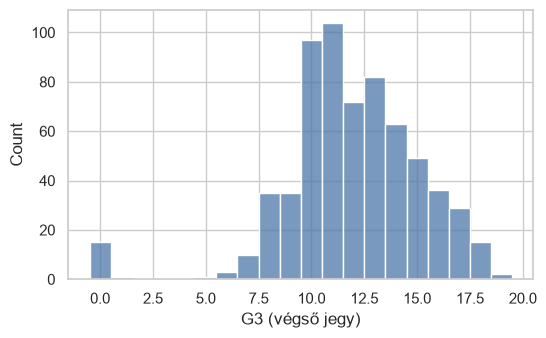

G3 = 0: 15 diák
átlag: 11.91 szórás: 3.23


In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(df["G3"], discrete=True, ax=ax, color="#4c78a8")
ax.set_xlabel("G3 (végső jegy)")
plt.show()
print("G3 = 0:", int((df["G3"] == 0).sum()), "diák")
print("átlag:", round(df["G3"].mean(), 2), "szórás:", round(df["G3"].std(), 2))

## Outlierek

A Tukey-szabály (1,5 × IQR) szerinti kilógó értékek oszloponként. Az 1–5 skálás ordinális oszlopoknál az IQR gyakran 0, ott a "kilógó" érték jogos érték (pl. `failures`), ezért a vágást csak a folytonos jellegű `absences` oszlopra alkalmazom.

In [6]:
iqr_outliers(df.drop(columns="G3")).head(10).round(1)

,oszlop,also_hatar,felso_hatar,kilogo_db
5,failures,0.0,0.0,100
6,famrel,2.5,6.5,51
7,freetime,1.5,5.5,45
4,studytime,-0.5,3.5,35
9,Dalc,-0.5,3.5,34
14,G2,5.5,17.5,25
12,absences,-9.0,15.0,21
13,G1,5.5,17.5,16
3,traveltime,-0.5,3.5,16
0,age,13.0,21.0,1


Az absences vágási határa: (-9.0, 15.0)


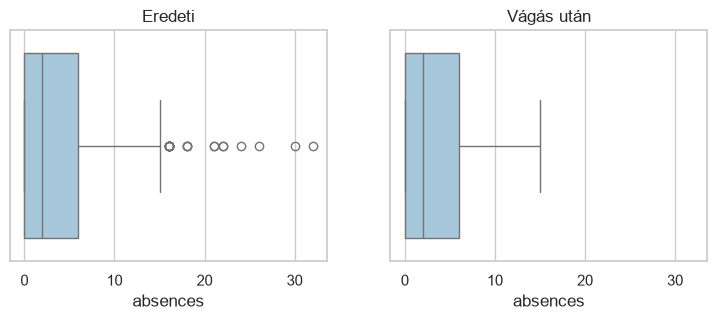

In [7]:
clip = OutlierClipper().fit(df)
print("Az absences vágási határa:", clip.bounds_["absences"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
sns.boxplot(x=df["absences"], ax=axes[0], color="#9ecae1")
axes[0].set_title("Eredeti")
sns.boxplot(x=clip.transform(df)["absences"], ax=axes[1], color="#9ecae1")
axes[1].set_title("Vágás után")
plt.show()

## Összefüggések

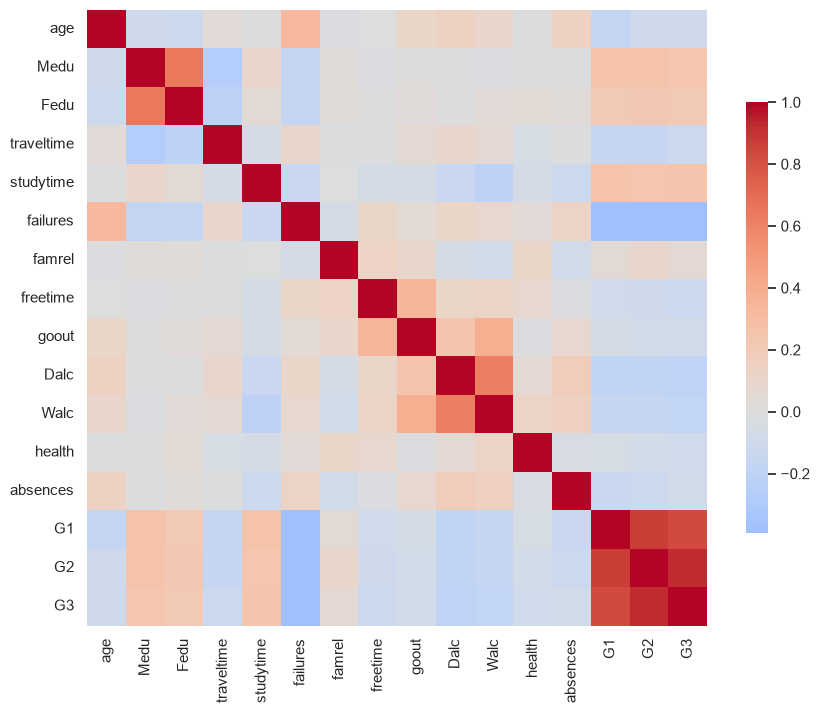

failures     -0.393316
Dalc         -0.204719
Walc         -0.176619
traveltime   -0.127173
freetime     -0.122705
age          -0.106505
health       -0.098851
absences     -0.091379
goout        -0.087641
famrel        0.063361
Fedu          0.211800
Medu          0.240151
studytime     0.249789
G1            0.826387
G2            0.918548
Name: G3, dtype: float64

In [8]:
num = df.select_dtypes("number")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": 0.7})
plt.show()
num.corr()["G3"].drop("G3").sort_values()

A `G1` és a `G2` a `G3`-mal r ≈ 0,83–0,92 korrelációban van: a korábbi jegyek szinte elárulják a végső jegyet. Ezért a fő elemzés két változatban fut: a `G1`/`G2` jellemzőkkel és nélkülük. Az utóbbi a tanulságosabb, mert ott a jegy a hátterű jellemzőkből jósolandó.

In [9]:
for col in df.select_dtypes(exclude="number").columns:
    print(col, df[col].value_counts().to_dict())

school {'GP': 423, 'MS': 226}
sex {'F': 383, 'M': 266}
address {'U': 452, 'R': 197}
famsize {'GT3': 457, 'LE3': 192}
Pstatus {'T': 569, 'A': 80}
Mjob {'other': 258, 'services': 136, 'at_home': 135, 'teacher': 72, 'health': 48}
Fjob {'other': 367, 'services': 181, 'at_home': 42, 'teacher': 36, 'health': 23}
reason {'course': 285, 'home': 149, 'reputation': 143, 'other': 72}
guardian {'mother': 455, 'father': 153, 'other': 41}
schoolsup {'no': 581, 'yes': 68}
famsup {'yes': 398, 'no': 251}
paid {'no': 610, 'yes': 39}
activities {'no': 334, 'yes': 315}
nursery {'yes': 521, 'no': 128}
higher {'yes': 580, 'no': 69}
internet {'yes': 498, 'no': 151}
romantic {'no': 410, 'yes': 239}


## Skálázás és kódolás

A láncban a számoszlopok medián-imputálás után standardizálva (átlag 0, szórás 1), a szöveges oszlopok módusz-imputálás után one-hot kódolva (a kétértékűek egy oszloppal) kerülnek a modellbe. Minden lépés csak a tanítóhalmazból tanul.

In [10]:
pipe = build_pipeline("baseline", "none")
Z = pipe[:3].fit_transform(df.drop(columns="G3"))
print("Nyers jellemzők:", df.shape[1] - 1, "-> a modell bemenete:", Z.shape[1], "oszlop")

Nyers jellemzők: 32 -> a modell bemenete: 50 oszlop


## Feature engineering

Új jellemzők (a `src/elemzes/features.py` `FeatureBuilder` osztálya):

- `alc_weekly`: heti átlagos alkoholfogyasztás, (5·`Dalc` + 2·`Walc`) / 7
- `parents_edu`: a szülők végzettségének összege
- `social_index`: `goout` · `freetime`
- `support_count`: hány tanulási támogatást kap (`schoolsup`, `famsup`, `paid`)
- `grade_trend`: `G2` − `G1` (csak a jegyekkel futó változatban)

In [11]:
new = FeatureBuilder().transform(df)
cols = ["alc_weekly", "parents_edu", "social_index", "support_count", "grade_trend"]
orig = ["Dalc", "Walc", "Medu", "Fedu", "goout", "freetime"]
pd.DataFrame({
    "korreláció a G3-mal": new[cols + orig].corrwith(new["G3"]).round(3),
    "új jellemző?": [c in cols for c in cols + orig],
})

,korreláció a G3-mal,új jellemző?
alc_weekly,-0.214,True
parents_edu,0.249,True
social_index,-0.159,True
support_count,-0.007,True
grade_trend,0.276,True
Dalc,-0.205,False
Walc,-0.177,False
Medu,0.240,False
Fedu,0.212,False
goout,-0.088,False


Az új jellemzők korrelációja a `G3`-mal nem sokkal tér el az eredetiekétől. Hogy a modell teljesítményén segítenek-e, azt a keresztvalidáció dönti el.

## Dimenziócsökkentés: PCA

A főkomponens-elemzést a standardizált, kódolt jellemzőkön végzem el. Itt csak feltáró jellegű (a teljes adaton illesztve), a modellezésben a PCA a lánc belsejében, a tanítóhalmazon tanul.

95% varianciához kell: 27 komponens a 47 oszlopból


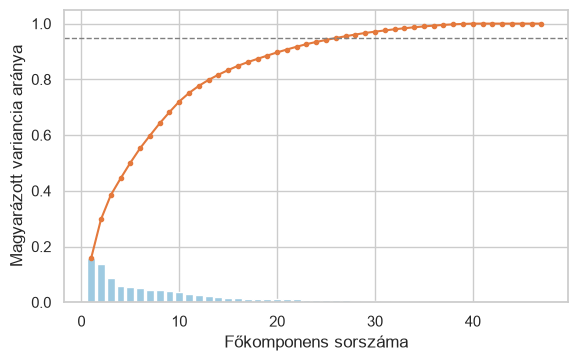

In [12]:
pipe = build_pipeline("baseline", "none")
Z = pipe[:3].fit_transform(df.drop(columns=["G3", "G1", "G2"]))
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
print("95% varianciához kell:", int(np.argmax(cum >= 0.95)) + 1, "komponens a", Z.shape[1], "oszlopból")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color="#9ecae1")
ax.plot(range(1, len(cum) + 1), cum, color="#e4793c", marker="o", ms=3)
ax.axhline(0.95, color="grey", ls="--", lw=1)
ax.set_xlabel("Főkomponens sorszáma")
ax.set_ylabel("Magyarázott variancia aránya")
plt.show()

A variancia lassan halmozódik: a kódolt jellemzők közt nincs néhány domináns irány, ezért a PCA csak mérsékelt tömörítést ad (a 95%-hoz a kódolt oszlopok nagyjából fele-kétharmada kell). A modellezés során a PCA-t az értelmezhetőség miatt nem használjuk a végső láncban (a főkomponensekre nem mondható jellemzőfontosság), a `04_elemzes_eredmenyek.ipynb` pedig megmutatja, hogy a teljesítményen sem segít.